# GCN 그래프 신경망 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week13/gcn/lab/gcn.ipynb)

각 노드의 정보를 나와 이웃들의 평균으로 바꾸며 층을 쌓는다: $H' = \sigma(\hat{A} H W)$, $\hat{A} = D^{-1/2}(A + I)D^{-1/2}$.

- **파트 1**: 손 계산 그래프 (4명) 로 평균 한 층 · 두 층, $\hat{A}$
- **파트 2**: 가라테 클럽 2층 GCN, 이름표 2명으로 나머지 32명 맞히기
- **파트 3**: 층 수 바꾸기 (과평활) · 사람마다 두 점수 그려 보기

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import torch, torch.nn as nn

## 파트 1. 나와 친구들의 평균

A–B, A–C, C–D 로 이어진 4명. A = +1 (관장 편), D = −1 (회장 편), B · C 는 모름 (0).

In [ ]:
A = np.array([[0, 1, 1, 0],
              [1, 0, 0, 0],
              [1, 0, 0, 1],
              [0, 0, 1, 0]], float)
x = np.array([1.0, 0.0, 0.0, -1.0])

def mean_matrix(A):
    A_self = A + np.eye(len(A))                          # include myself
    return None  # TODO: divide each row by its number of entries

def gcn_matrix(A):
    A_self = A + np.eye(len(A))
    d = A_self.sum(axis=1)
    return None  # TODO: 1 / sqrt(d_i d_j) for connected pairs

M = mean_matrix(A)
h1 = M @ x; h2 = M @ h1
print("layer 1:", h1.round(2)); print("layer 2:", h2.round(2))
print("A_hat:"); print(gcn_matrix(A).round(2))

**예상 결과**

```
layer 1: [ 0.33  0.5   0.   -0.5 ]
layer 2: [ 0.28  0.42 -0.06 -0.25]
A_hat:
[[0.33 0.41 0.33 0.  ]
 [0.41 0.5  0.   0.  ]
 [0.33 0.   0.33 0.41]
 [0.   0.   0.41 0.5 ]]
```

## 파트 2. 가라테 클럽

34명, 친구 관계 78개. 특징은 사람마다 고유 번호 (단위 행렬), 손실은 0번 (관장) · 33번 (회장) 에서만.

In [ ]:
G = nx.karate_club_graph()
n = G.number_of_nodes()
A_karate = nx.to_numpy_array(G, weight=None)
y = torch.tensor([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in range(n)])
print(n, "people,", G.number_of_edges(), "friendships,", int((y == 0).sum()), "vs", int((y == 1).sum()))
print("friends per person: min", int(A_karate.sum(1).min()), " max", int(A_karate.sum(1).max()))
pos = nx.spring_layout(G, seed=4)
nx.draw(G, pos, node_color=["#2E3192" if c == 0 else "#A9976B" for c in y.tolist()], node_size=200, edge_color="#cccccc")
plt.show()

**예상 결과**

```
34 people, 78 friendships, 17 vs 17
friends per person: min 1  max 17
```

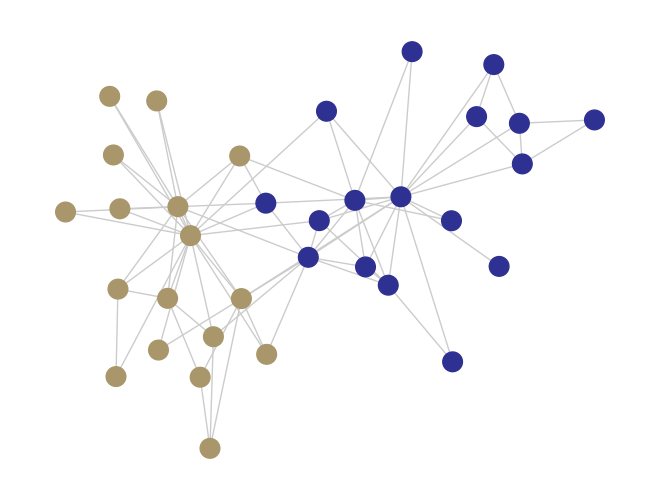

In [ ]:
class GCN(nn.Module):
    def __init__(self, A_hat, dims):
        super().__init__()
        self.A_hat = torch.tensor(A_hat, dtype=torch.float32)
        self.layers = nn.ModuleList([nn.Linear(a, b) for a, b in zip(dims[:-1], dims[1:])])

    def forward(self, X):
        h = X
        for k, layer in enumerate(self.layers):
            h = None  # TODO: A_hat @ (h W)
            if k < len(self.layers) - 1:
                h = torch.relu(h)
        return h

def train_gcn(A, y, dims, labeled=(0, 33), seed=0, steps=200):
    torch.manual_seed(seed)
    model = GCN(gcn_matrix(A), dims)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    X, lab = torch.eye(len(A)), torch.tensor(labeled)
    for _ in range(steps):
        out = model(X)
        loss = None  # TODO: loss on the labeled people only
        opt.zero_grad(); loss.backward(); opt.step()
    return model, out.detach()

def count_correct(out, y, labeled=(0, 33)):
    rest = [i for i in range(len(y)) if i not in labeled]
    return int((out.argmax(1)[rest] == y[rest]).sum())

model, out = train_gcn(A_karate, y, [n, 16, 2])
pred = out.argmax(1)
print("correct:", count_correct(out, y), "/ 32")
print("weights:", sum(p.numel() for p in model.parameters()))
wrong = [i for i in range(n) if pred[i] != y[i]]
for i in wrong:
    print(f"wrong: person {i}, friends {sorted(G[i])}, their sides {[int(y[j]) for j in sorted(G[i])]}, true side {int(y[i])}")

**예상 결과**

```
correct: 31 / 32
weights: 594
wrong: person 8, friends [0, 2, 30, 32, 33], their sides [0, 0, 1, 1, 1], true side 0
```

## 파트 3. 층 수 · 두 점수 그려 보기

층을 많이 쌓으면 평균을 여러 번 내서 모두 비슷해진다 (과평활).

In [ ]:
for L in [1, 2, 3, 4, 6, 8]:
    dims = [n] + [16] * (L - 1) + [2]
    scores = [count_correct(train_gcn(A_karate, y, dims, seed=s)[1], y) for s in range(5)]
    print(f"{L} layers: correct {scores}  mean {np.mean(scores):.1f}")

**예상 결과**

```
1 layers: correct [30, 30, 30, 30, 31]  mean 30.2
2 layers: correct [31, 31, 31, 31, 31]  mean 31.0
3 layers: correct [31, 31, 31, 31, 31]  mean 31.0
4 layers: correct [31, 31, 31, 31, 30]  mean 30.8
6 layers: correct [30, 30, 30, 30, 31]  mean 30.2
8 layers: correct [16, 17, 17, 17, 16]  mean 16.6
```

In [ ]:
# The 2 output scores of every person (part 2 model): the side is decided by which score is larger
def plot_scores(out, y, highlight=(0, 33, 8)):
    out = out.numpy()
    plt.scatter(out[:, 0], out[:, 1], c=["#2E3192" if c == 0 else "#A9976B" for c in y.tolist()], s=80)
    lo, hi = out.min(), out.max()
    plt.plot([lo, hi], [lo, hi], ":", color="gray")      # boundary: score 0 = score 1
    for i in highlight:
        plt.annotate(str(i), out[i], fontsize=12)
    plt.xlabel("score for Mr. Hi (0)"); plt.ylabel("score for Officer (33)"); plt.show()

plot_scores(out, y)

**예상 결과**

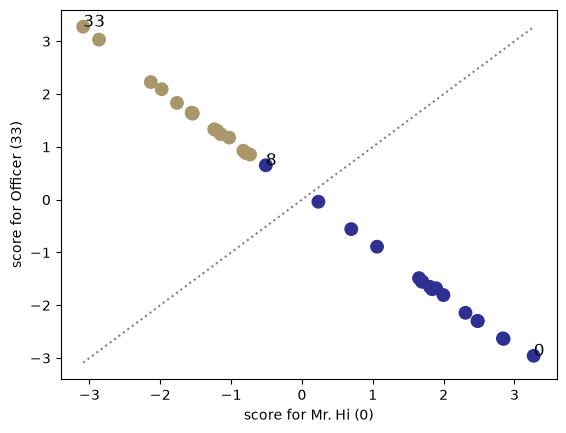

**확인 질문**
1. 파트 1 에서 C 의 값이 1층 뒤 0, 2층 뒤 −0.06 이 된 이유는?
2. 파트 2 의 가중치 수 594 개는 노드가 1만 명이 되면 어떻게 바뀌나? (특징 칸 수는 그대로라고 하자)
3. 파트 2 에서 틀린 사람은 왜 틀렸을까? 친구 관계만으로 맞힐 방법이 있을까?
4. (도전) 이름표를 0번 · 33번 대신 다른 두 사람 (예: 16번 · 26번) 으로 바꾸면 정답 수는?

데이터 출처: W. W. Zachary (1977), An Information Flow Model for Conflict and Fission in Small Groups (networkx `karate_club_graph`).